# HDB Rentals: EDA of `data/train.csv`

Target: `MONTHLY_RENT`. Train and test are consecutive periods, so read section 1 first. `data/test.csv` has no
target and is used only for its dates and feature distributions.

1. The problem: regression on a moving market, scored out-of-time
2. Structure: shape, dtypes, missingness, duplicates
3. `.describe()` for numeric and categorical columns
4. Data-quality issues
5. A cleaned analysis frame
6. Correlation
7. Time structure: hedonic market level, trend, seasonality, drift, validation scheme, forecasting the level
8. Encoding analysis
9. Distribution of every column
10. Summary

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import sparse, stats
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.model_selection import KFold, cross_val_predict
from sklearn.preprocessing import OneHotEncoder
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.stattools import adfuller

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 110

DATA = Path("..") / "data" if Path("../data").exists() else Path("data")
TARGET = "MONTHLY_RENT"

train = pd.read_csv(DATA / "train.csv")
test = pd.read_csv(DATA / "test.csv")
print(f"train: {train.shape}   test: {test.shape}")
train.head()

train: (150000, 11)   test: (50000, 10)


,RENT_APPROVAL_DATE,TOWN,BLOCK,STREET,FLAT_TYPE,FLAT_MODEL,FLOOR_AREA_SQM,FURNISHED,LEASE_COMMENCE_DATE,FEE,MONTHLY_RENT
0,2021-01,punggol,604a,punggol road,4 room,model a,93.000,yes,2012,0.000,1800
1,2021-01,sengkang,290c,compassvale crescent,5 room,improved,110.000,yes,2001,0.000,2000
2,2021-01,queenstown,5,ghim moh road,3 room,improved,65.000,yes,1976,0.000,2000
3,2021-01,sengkang,436b,fernvale road,4 room,model a,96.000,yes,2010,0.000,1400
4,2021-01,sembawang,467b,admiralty drive,4 room,premium apartment,102.000,yes,2001,0.000,1800


## 1. The problem: regression on a moving market, scored out-of-time

Two facts define this problem before a single column is profiled.

In [2]:
# The split is temporal, not random -- the single most important fact about this dataset.
pd.DataFrame({
    name: {
        "first_month": df["RENT_APPROVAL_DATE"].min(),
        "last_month": df["RENT_APPROVAL_DATE"].max(),
        "n_months": df["RENT_APPROVAL_DATE"].nunique(),
        "rows_per_month": round(len(df) / df["RENT_APPROVAL_DATE"].nunique()),
    }
    for name, df in [("train", train), ("test", test)]
}).T

,first_month,last_month,n_months,rows_per_month
train,2021-01,2025-03,51,2941
test,2025-03,2026-07,17,2941


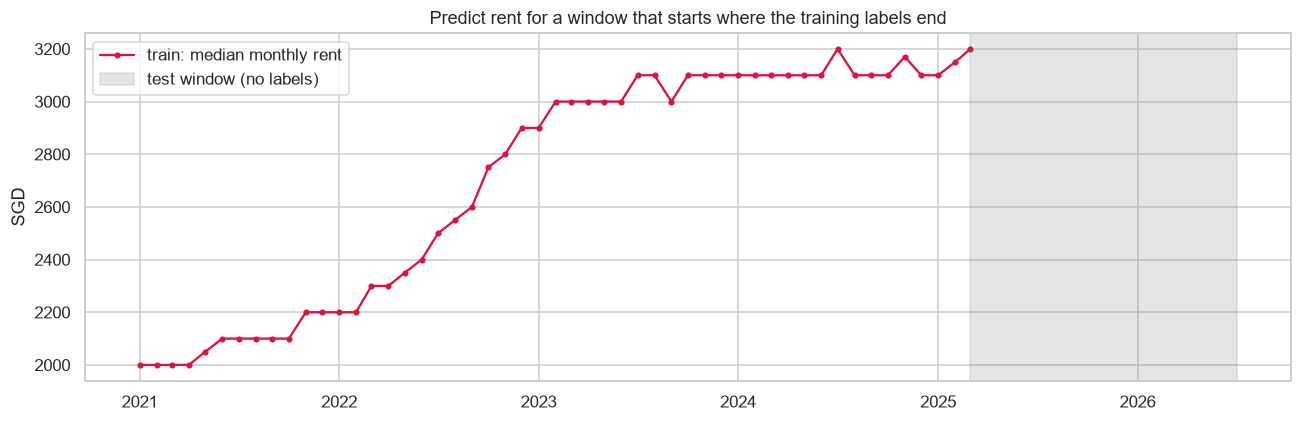

In [3]:
# The target level moves over time, and the test window starts where the labels stop.
raw_market = train.groupby(pd.to_datetime(train["RENT_APPROVAL_DATE"], format="%Y-%m"))[TARGET].median()
test_months = pd.to_datetime(test["RENT_APPROVAL_DATE"], format="%Y-%m")

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(raw_market.index, raw_market, marker="o", ms=3, color="crimson", label="train: median monthly rent")
ax.axvspan(test_months.min(), test_months.max(), color="grey", alpha=0.2, label="test window (no labels)")
ax.set_ylabel("SGD")
ax.set_title("Predict rent for a window that starts where the training labels end")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

1. **The split is temporal.** Train 2021-01 to 2025-03, test 2025-03 to 2026-07: up to 16 months past the last label.
2. **The target level moves.** Median rent climbed steeply through 2023, then flattened.

There is no flat ID and every row is a different rental, so there are no lags to forecast. But every scored
prediction is in the future. Section 7 shows the problem splits in two:

$$\text{rent} \approx \underbrace{\text{market level}(\text{month})}_{\text{time series: forecast up to 16 months ahead}} \times \underbrace{\text{relative premium}(\text{flat, location})}_{\text{cross-sectional: stable over time}}$$

- Validation must be time-ordered.
- Anything fitted on the target may only use earlier months.
- How the model extrapolates the level is a first-order decision.
- Month-of-year seasonality is negligible (7.2).

## 2. Structure, dtypes and missingness

Cardinality and example values per column, to assign a semantic type (drives section 8).

In [4]:
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 150000 entries, 0 to 149999
Data columns (total 11 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   RENT_APPROVAL_DATE   150000 non-null  str    
 1   TOWN                 150000 non-null  str    
 2   BLOCK                150000 non-null  str    
 3   STREET               150000 non-null  str    
 4   FLAT_TYPE            150000 non-null  str    
 5   FLAT_MODEL           150000 non-null  str    
 6   FLOOR_AREA_SQM       150000 non-null  float64
 7   FURNISHED            150000 non-null  str    
 8   LEASE_COMMENCE_DATE  150000 non-null  int64  
 9   FEE                  150000 non-null  float64
 10  MONTHLY_RENT         150000 non-null  int64  
dtypes: float64(2), int64(2), str(7)
memory usage: 12.6 MB


In [5]:
def column_profile(df: pd.DataFrame) -> pd.DataFrame:
    rows = []
    for c in df.columns:
        s = df[c]
        rows.append(
            {
                "dtype": str(s.dtype),
                "n_unique": s.nunique(),
                "unique_pct": 100 * s.nunique() / len(s),
                "n_missing": s.isna().sum(),
                "missing_pct": 100 * s.isna().mean(),
                "mem_mb": s.memory_usage(deep=True) / 1e6,
                "examples": ", ".join(map(str, s.dropna().unique()[:4])),
            }
        )
    return pd.DataFrame(rows, index=df.columns)


profile = column_profile(train)
profile

,dtype,n_unique,unique_pct,n_missing,missing_pct,mem_mb,examples
RENT_APPROVAL_DATE,str,51,0.034,0,0.000,9.600,"2021-01, 2021-02, 2021-03, 2021-04"
TOWN,str,26,0.017,0,0.000,9.913,"punggol, sengkang, queenstown, sembawang"
BLOCK,str,2720,1.813,0,0.000,8.998,"604a, 290c, 5, 436b"
STREET,str,1146,0.764,0,0.000,11.101,"punggol road, compassvale crescent, ghim moh r..."
FLAT_TYPE,str,11,0.007,0,0.000,9.475,"4 room, 5 room, 3 room, executive"
FLAT_MODEL,str,20,0.013,0,0.000,10.004,"model a, improved, premium apartment, new gene..."
FLOOR_AREA_SQM,float64,156,0.104,0,0.000,1.200,"93.0, 110.0, 65.0, 96.0"
FURNISHED,str,1,0.001,0,0.000,9.000,yes
LEASE_COMMENCE_DATE,int64,57,0.038,0,0.000,1.200,"2012, 2001, 1976, 2010"
FEE,float64,1,0.001,0,0.000,1.200,0.0


In [6]:
print("fully duplicated rows:", train.duplicated().sum())
print("duplicated ignoring the target:", train.drop(columns=[TARGET]).duplicated().sum())

# Same feature row, different rent -> irreducible noise; worth knowing before chasing a low error.
dupe_spread = (
    train.groupby(list(train.columns.drop(TARGET)), observed=True)[TARGET]
    .agg(["size", "min", "max", "std"])
    .query("size > 1")
)
print(f"\nfeature-identical groups: {len(dupe_spread):,}")
dupe_spread.sort_values("size", ascending=False).head(10)

fully duplicated rows: 425
duplicated ignoring the target: 15547



feature-identical groups: 13,434


,,,,,,,,,,size,min,max,std
RENT_APPROVAL_DATE,TOWN,BLOCK,STREET,FLAT_TYPE,FLAT_MODEL,FLOOR_AREA_SQM,FURNISHED,LEASE_COMMENCE_DATE,FEE,,,,
2025-01,queenstown,5,ghim moh road,3-room,improved,65.000,yes,1976,0.000,9,2600,3300,191.122
2024-04,queenstown,2,holland avenue,3-room,improved,65.000,yes,1974,0.000,8,2600,3500,335.344
2024-06,queenstown,11,holland drive,3-room,improved,65.000,yes,1975,0.000,7,2050,3500,502.257
2025-01,queenstown,4,holland close,3-room,improved,65.000,yes,1974,0.000,7,1000,3300,811.891
2022-01,queenstown,3,dover road,3-room,improved,65.000,yes,1975,0.000,6,1800,2650,288.097
2022-08,queenstown,6,holland close,3-room,improved,65.000,yes,1974,0.000,6,1800,3500,606.630
2021-03,clementi,330,clementi avenue 2,3 room,new generation,67.000,yes,1978,0.000,6,1650,2400,290.545
2021-08,clementi,702,west coast road,3 room,new generation,67.000,yes,1980,0.000,6,1400,2150,270.093
2021-12,toa payoh,157,lorong 1 toa payoh,3 room,improved,67.000,yes,1971,0.000,6,1200,2500,433.590


## 3. `.describe()`

Numeric and categorical columns are described separately: `describe(include="all")` mixes two different sets
of statistics into one table and is harder to read.

In [7]:
num_cols = train.select_dtypes(include="number").columns.tolist()
cat_cols = [c for c in train.columns if c not in num_cols]
print("numeric    :", num_cols)
print("categorical:", cat_cols)

train[num_cols].describe(percentiles=[0.01, 0.25, 0.5, 0.75, 0.99]).T

numeric    : ['FLOOR_AREA_SQM', 'LEASE_COMMENCE_DATE', 'FEE', 'MONTHLY_RENT']
categorical: ['RENT_APPROVAL_DATE', 'TOWN', 'BLOCK', 'STREET', 'FLAT_TYPE', 'FLAT_MODEL', 'FURNISHED']


,count,mean,std,min,1%,25%,50%,75%,99%,max
FLOOR_AREA_SQM,"150,000.000",93.339,24.272,31.000,47.000,68.000,92.000,110.000,149.000,215.000
LEASE_COMMENCE_DATE,"150,000.000","1,990.907",12.642,"1,966.000","1,968.000","1,981.000","1,988.000","2,001.000","2,018.000","2,022.000"
FEE,"150,000.000",0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
MONTHLY_RENT,"150,000.000","2,719.037",749.731,300.000,"1,300.000","2,100.000","2,700.000","3,200.000","4,600.000","7,600.000"


In [8]:
train[cat_cols].describe().T

,count,unique,top,freq
RENT_APPROVAL_DATE,150000,51,2021-03,3705
TOWN,150000,26,jurong west,10482
BLOCK,150000,2720,2,921
STREET,150000,1146,ang mo kio avenue 3,1590
FLAT_TYPE,150000,11,4-room,40688
FLAT_MODEL,150000,20,improved,44008
FURNISHED,150000,1,yes,150000


In [9]:
# Distribution shape of the numeric columns beyond mean/std.
pd.DataFrame(
    {
        "skew": train[num_cols].skew(),
        "kurtosis": train[num_cols].kurtosis(),
        "zeros": (train[num_cols] == 0).sum(),
        "cv": train[num_cols].std() / train[num_cols].mean(),
    }
)

,skew,kurtosis,zeros,cv
FLOOR_AREA_SQM,0.245,-0.541,0,0.260
LEASE_COMMENCE_DATE,0.355,-0.709,0,0.006
FEE,0.000,0.000,150000,NaN
MONTHLY_RENT,0.386,-0.062,0,0.276


## 4. Data-quality issues

Three things fall out of the profile above. Each one changes what we do downstream, so they are checked
explicitly rather than assumed.

In [10]:
# (a) Zero-variance columns carry no information and must not reach a model.
constant = [c for c in train.columns if train[c].nunique(dropna=False) <= 1]
for c in constant:
    print(f"{c:<12} constant in train = {train[c].unique()[0]!r} | in test = {test[c].unique()}")

FURNISHED    constant in train = 'yes' | in test = <StringArray>
['yes']
Length: 1, dtype: str
FEE          constant in train = np.float64(0.0) | in test = [0.]


In [11]:
# (b) FLAT_TYPE is spelled two ways -> 11 apparent levels for 6 real ones.
print(train["FLAT_TYPE"].value_counts(), "\n")
print("test spellings:", sorted(test["FLAT_TYPE"].unique()))

FLAT_TYPE
4-room       40688
3-room       36932
5-room       26215
4 room       13391
3 room       12092
5 room        9308
executive     8234
2-room        2566
2 room         532
1-room          34
1 room           8
Name: count, dtype: int64 

test spellings: ['1-room', '2-room', '3-room', '4-room', '5-room', 'executive']


In [12]:
# (c) STREET/BLOCK are inconsistently cased, which inflates cardinality the same way.
for c in ["STREET", "BLOCK"]:
    raw = train[c].nunique()
    low = train[c].str.strip().str.lower().nunique()
    print(f"{c:<7} raw={raw:>5}  lower-cased={low:>5}  ({raw - low} phantom levels)")

print("\nsample of the mixed casing:")
print(train.loc[~train["STREET"].str.islower(), "STREET"].drop_duplicates().head(5).tolist())

STREET  raw= 1146  lower-cased=  576  (570 phantom levels)
BLOCK   raw= 2720  lower-cased= 2720  (0 phantom levels)

sample of the mixed casing:
['Hougang Avenue 10', 'Admiralty Link', 'Hougang Avenue 6', 'Balam Road', 'Cantonment Road']


## 5. Cleaned analysis frame

Only the repairs justified above, plus the minimum feature derivation needed to correlate anything against
time and lease age. Nothing speculative; this is not the modelling feature set.

In [13]:
def clean(df: pd.DataFrame) -> pd.DataFrame:
    out = df.copy()

    text = out.select_dtypes(include="str").columns
    out[text] = out[text].apply(lambda s: s.str.strip().str.lower())

    # "4 room" and "4-room" are the same level.
    out["FLAT_TYPE"] = out["FLAT_TYPE"].str.replace(r"[\s\-]+", "-", regex=True)

    out["RENT_APPROVAL_DATE"] = pd.to_datetime(out["RENT_APPROVAL_DATE"], format="%Y-%m")
    out["APPROVAL_YEAR"] = out["RENT_APPROVAL_DATE"].dt.year
    out["APPROVAL_MONTH"] = out["RENT_APPROVAL_DATE"].dt.month
    # Months since the first month in train: a single monotone time index for correlation.
    out["MONTH_INDEX"] = (
        (out["RENT_APPROVAL_DATE"].dt.year - 2021) * 12 + out["RENT_APPROVAL_DATE"].dt.month - 1
    )

    out["FLAT_AGE"] = out["APPROVAL_YEAR"] - out["LEASE_COMMENCE_DATE"]
    out["REMAINING_LEASE"] = 99 - out["FLAT_AGE"]
    out["ADDRESS"] = out["BLOCK"] + " " + out["STREET"]

    return out.drop(columns=constant)


tr = clean(train)
te = clean(test)
print("dropped constant columns:", constant)
tr.head(3)

dropped constant columns: ['FURNISHED', 'FEE']


,RENT_APPROVAL_DATE,TOWN,BLOCK,STREET,FLAT_TYPE,FLAT_MODEL,FLOOR_AREA_SQM,LEASE_COMMENCE_DATE,MONTHLY_RENT,APPROVAL_YEAR,APPROVAL_MONTH,MONTH_INDEX,FLAT_AGE,REMAINING_LEASE,ADDRESS
0,2021-01-01,punggol,604a,punggol road,4-room,model a,93.000,2012,1800,2021,1,0,9,90,604a punggol road
1,2021-01-01,sengkang,290c,compassvale crescent,5-room,improved,110.000,2001,2000,2021,1,0,20,79,290c compassvale crescent
2,2021-01-01,queenstown,5,ghim moh road,3-room,improved,65.000,1976,2000,2021,1,0,45,54,5 ghim moh road


In [14]:
# How much of the test set is addressable by categories seen in train? Decides whether a high-cardinality
# encoder needs an unseen-category fallback.
for c in ["TOWN", "FLAT_TYPE", "FLAT_MODEL", "STREET", "BLOCK", "ADDRESS"]:
    seen = set(tr[c])
    unseen_rows = (~te[c].isin(seen)).sum()
    print(f"{c:<11} train levels={len(seen):>6}  test levels={te[c].nunique():>6}  "
          f"unseen levels={te[c].nunique() - te.loc[te[c].isin(seen), c].nunique():>4}  "
          f"affected test rows={unseen_rows:>5} ({100 * unseen_rows / len(te):.2f}%)")

TOWN        train levels=    26  test levels=    26  unseen levels=   0  affected test rows=    0 (0.00%)
FLAT_TYPE   train levels=     6  test levels=     6  unseen levels=   0  affected test rows=    0 (0.00%)
FLAT_MODEL  train levels=    20  test levels=    19  unseen levels=   0  affected test rows=    0 (0.00%)


STREET      train levels=   576  test levels=   573  unseen levels=   0  affected test rows=    0 (0.00%)


BLOCK       train levels=  2720  test levels=  2660  unseen levels=  11  affected test rows=   36 (0.07%)
ADDRESS     train levels=  9406  test levels=  8940  unseen levels=  50  affected test rows=  102 (0.20%)


## 6. Correlation

| pair | measure | range |
|---|---|---|
| numeric ↔ numeric | Pearson (linear) and Spearman (monotone) | −1 … 1 |
| categorical → numeric target | correlation ratio η | 0 … 1 |
| categorical ↔ categorical | Cramér's V | 0 … 1 |

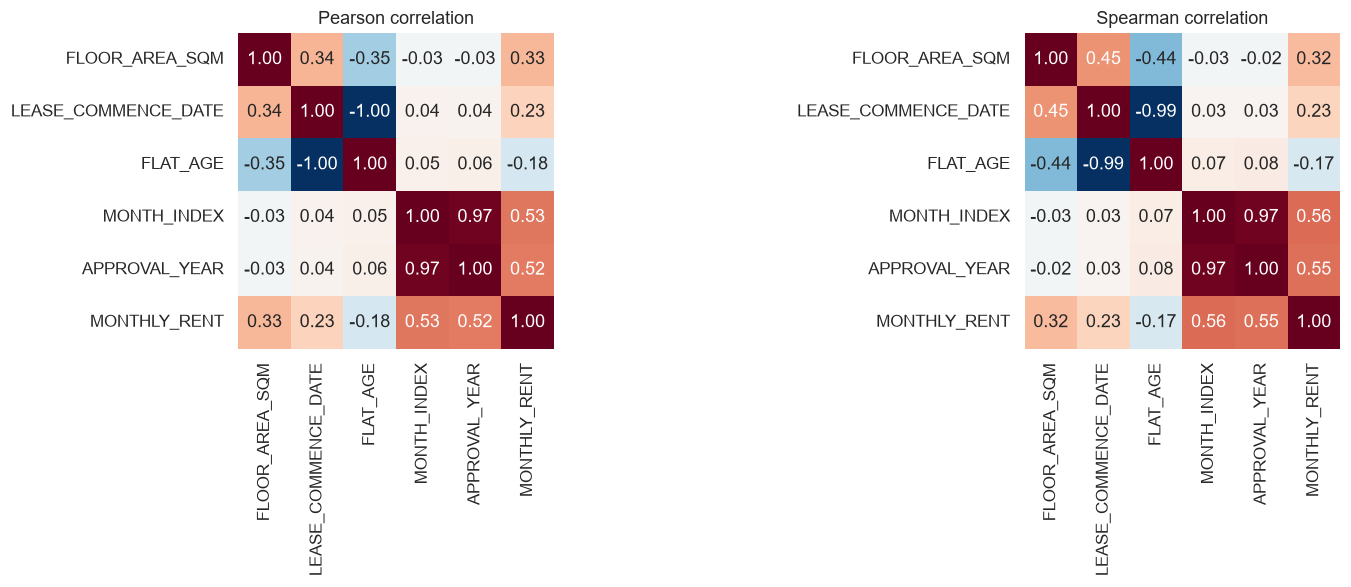

In [15]:
corr_cols = ["FLOOR_AREA_SQM", "LEASE_COMMENCE_DATE", "FLAT_AGE", "MONTH_INDEX", "APPROVAL_YEAR", TARGET]

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
for ax, method in zip(axes, ["pearson", "spearman"]):
    sns.heatmap(
        tr[corr_cols].corr(method=method), annot=True, fmt=".2f", cmap="RdBu_r",
        vmin=-1, vmax=1, square=True, cbar=False, ax=ax,
    )
    ax.set_title(f"{method.title()} correlation")
plt.tight_layout()
plt.show()

In [16]:
# REMAINING_LEASE is 99 - FLAT_AGE and FLAT_AGE is APPROVAL_YEAR - LEASE_COMMENCE_DATE, so several of these
# are exact linear combinations of each other. Only one of each group belongs in a linear model.
tr[corr_cols].corr()[TARGET].drop(TARGET).sort_values(key=abs, ascending=False).to_frame("pearson_vs_target")

,pearson_vs_target
MONTH_INDEX,0.535
APPROVAL_YEAR,0.517
FLOOR_AREA_SQM,0.329
LEASE_COMMENCE_DATE,0.229
FLAT_AGE,-0.178


In [17]:
def correlation_ratio(categories: pd.Series, values: pd.Series) -> float:
    # Eta: sqrt of the share of the target's variance explained by group membership.
    # 0 = the level tells you nothing about the target, 1 = the level determines it.
    # Equivalent to sqrt(R^2) of regressing the target on the one-hot levels -- i.e. what Pearson would give if it
    # could take a category. Pearson on label codes is not a substitute: it depends on an arbitrary level order.
    # pandas/scipy have no built-in for this.
    df = pd.DataFrame({"c": categories, "v": values}).dropna()
    grand_mean = df["v"].mean()
    grp = df.groupby("c", observed=True)["v"].agg(["size", "mean"])
    between = (grp["size"] * (grp["mean"] - grand_mean) ** 2).sum()
    total = ((df["v"] - grand_mean) ** 2).sum()
    return float(np.sqrt(between / total)) if total else 0.0


cat_features = ["TOWN", "FLAT_TYPE", "FLAT_MODEL", "STREET", "BLOCK", "ADDRESS", "APPROVAL_YEAR"]
eta = pd.DataFrame(
    {
        "n_levels": [tr[c].nunique() for c in cat_features],
        "eta_vs_rent": [correlation_ratio(tr[c], tr[TARGET]) for c in cat_features],
    },
    index=cat_features,
).sort_values("eta_vs_rent", ascending=False)
eta["eta_squared"] = eta["eta_vs_rent"] ** 2
eta

,n_levels,eta_vs_rent,eta_squared
ADDRESS,9406,0.549,0.302
APPROVAL_YEAR,5,0.547,0.299
STREET,576,0.380,0.145
FLAT_TYPE,6,0.368,0.135
BLOCK,2720,0.335,0.112
FLAT_MODEL,20,0.253,0.064
TOWN,26,0.195,0.038


η rises mechanically with the number of levels: a 9,406-level `ADDRESS` can chase noise in a way a 26-level
`TOWN` cannot. Compare each column against a permuted baseline: shuffle the labels and recompute η. Whatever
is left above that baseline is the real signal.

In [18]:
rng = np.random.default_rng(0)
rows = []
for c in cat_features:
    shuffled = np.mean([
        correlation_ratio(pd.Series(rng.permutation(tr[c].to_numpy())), tr[TARGET]) for _ in range(3)
    ])
    rows.append({"eta": correlation_ratio(tr[c], tr[TARGET]), "eta_if_shuffled": shuffled})
baseline = pd.DataFrame(rows, index=cat_features)
baseline["excess"] = baseline["eta"] - baseline["eta_if_shuffled"]
baseline.sort_values("excess", ascending=False)

,eta,eta_if_shuffled,excess
APPROVAL_YEAR,0.547,0.006,0.541
FLAT_TYPE,0.368,0.005,0.363
STREET,0.380,0.062,0.318
ADDRESS,0.549,0.250,0.300
FLAT_MODEL,0.253,0.012,0.241
BLOCK,0.335,0.134,0.201
TOWN,0.195,0.012,0.183


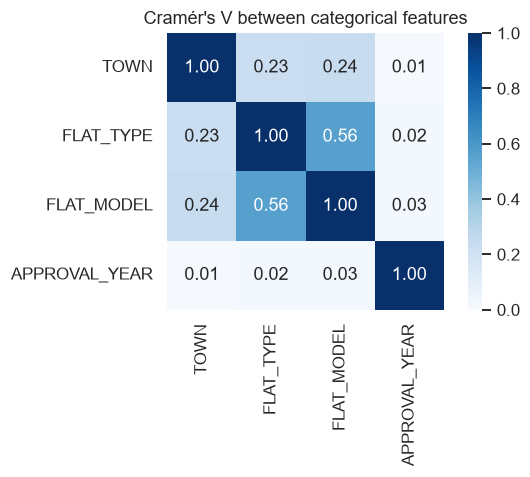

,TOWN,FLAT_TYPE,FLAT_MODEL,APPROVAL_YEAR
TOWN,1.000,0.226,0.244,0.014
FLAT_TYPE,0.226,1.000,0.562,0.020
FLAT_MODEL,0.244,0.562,1.000,0.025
APPROVAL_YEAR,0.014,0.020,0.025,1.000


In [19]:
# Restricted to the low-cardinality columns: a 9,406 x 2,720 contingency table is neither computable
# nor meaningful. With 150k rows, a small-sample bias correction changes V only in the 4th decimal.
low_card = ["TOWN", "FLAT_TYPE", "FLAT_MODEL", "APPROVAL_YEAR"]
cv = pd.DataFrame(
    [[stats.contingency.association(pd.crosstab(tr[a], tr[b]).to_numpy(), method="cramer") for b in low_card]
     for a in low_card],
    index=low_card, columns=low_card,
)

plt.figure(figsize=(6, 4.5))
sns.heatmap(cv, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, square=True)
plt.title("Cramér's V between categorical features")
plt.tight_layout()
plt.show()
cv

`FLAT_TYPE` and `FLAT_MODEL` are strongly associated (a maisonette is never a 2-room), and both are
associated with `FLOOR_AREA_SQM`. That redundancy matters for one-hot encoding: it produces collinear columns
that make linear-model coefficients unstable, though it is harmless for trees.

In [20]:
# The numeric side of that redundancy.
pd.DataFrame({
    "eta_vs_FLOOR_AREA": [correlation_ratio(tr[c], tr["FLOOR_AREA_SQM"]) for c in ["FLAT_TYPE", "FLAT_MODEL", "TOWN"]],
}, index=["FLAT_TYPE", "FLAT_MODEL", "TOWN"])

,eta_vs_FLOOR_AREA
FLAT_TYPE,0.954
FLAT_MODEL,0.610
TOWN,0.447


## 7. Time structure

**Main argument:** rent ≈ market level(month) × relative premium(flat, location).

1. The market level rose ~56% in two regimes, rapid growth then plateau, with no usable seasonality (7.1, 7.2).
2. The premiums around it are static (7.3).
3. So the whole gap between random K-fold and time-ordered validation is the market level (7.4, 7.5), and no simple
   rule extrapolates it safely across both regimes (7.6).

**Market level** = a hedonic index of monthly rent with the flat mix held fixed, in SGD (7.1). ~3,000 rows a month.

### 7.1 The market level: two regimes

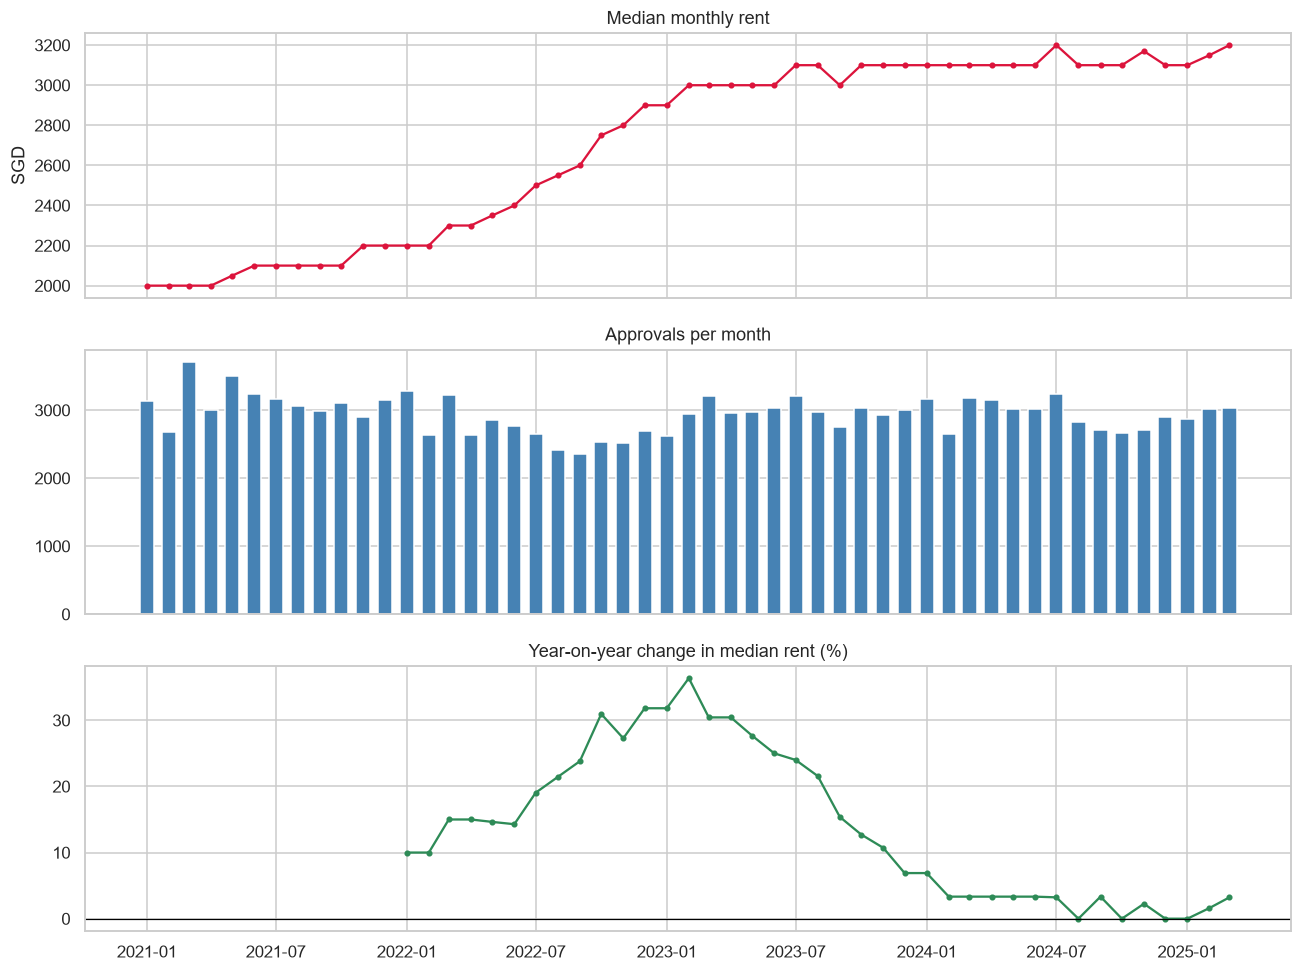

median rent 2,000 -> 3,200  (+60.0% across the training window)


In [21]:
monthly = tr.groupby("RENT_APPROVAL_DATE").agg(n=(TARGET, "size"), median_rent=(TARGET, "median")).asfreq("MS")
raw_median = monthly["median_rent"]

fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True)
axes[0].plot(raw_median.index, raw_median, marker="o", ms=3, color="crimson")
axes[0].set_title("Median monthly rent")
axes[0].set_ylabel("SGD")

axes[1].bar(monthly.index, monthly["n"], width=20, color="steelblue")
axes[1].set_title("Approvals per month")

yoy = 100 * raw_median.pct_change(12)
axes[2].plot(yoy.index, yoy, marker="o", ms=3, color="seagreen")
axes[2].axhline(0, c="black", lw=0.8)
axes[2].set_title("Year-on-year change in median rent (%)")
plt.tight_layout()
plt.show()

first, last = raw_median.iloc[0], raw_median.iloc[-1]
print(f"median rent {first:,.0f} -> {last:,.0f}  ({100 * (last / first - 1):+.1f}% across the training window)")

In [22]:
# Rent per sqm moves the same way, so the rise is a price change, not a shift towards bigger flats.
yearly = tr.groupby("APPROVAL_YEAR").agg(n=(TARGET, "size"), median_rent=(TARGET, "median"))
yearly["growth_%"] = 100 * yearly["median_rent"].pct_change()
yearly["median_rent_per_sqm"] = (tr[TARGET] / tr["FLOOR_AREA_SQM"]).groupby(tr["APPROVAL_YEAR"]).median()
yearly

,n,median_rent,growth_%,median_rent_per_sqm
APPROVAL_YEAR,,,,
2021,37619,"2,100.000",NaN,22.826
2022,32564,"2,450.000",16.667,27.174
2023,35654,"3,000.000",22.449,33.036
2024,35239,"3,100.000",3.333,34.286
2025,8924,"3,150.000",1.613,34.444


- **2021 to 2023: rapid growth.** +17%, then +22% a year; year-on-year growth peaked above 30%.
- **2024 to 2025-03: plateau.** +3%, then flat.

A straight line through `MONTH_INDEX` fits neither regime.

Rents sit on a 50-SGD grid, so the raw median moves in steps, and it also moves with the mix of flats rented each
month. A hedonic index fixes both.

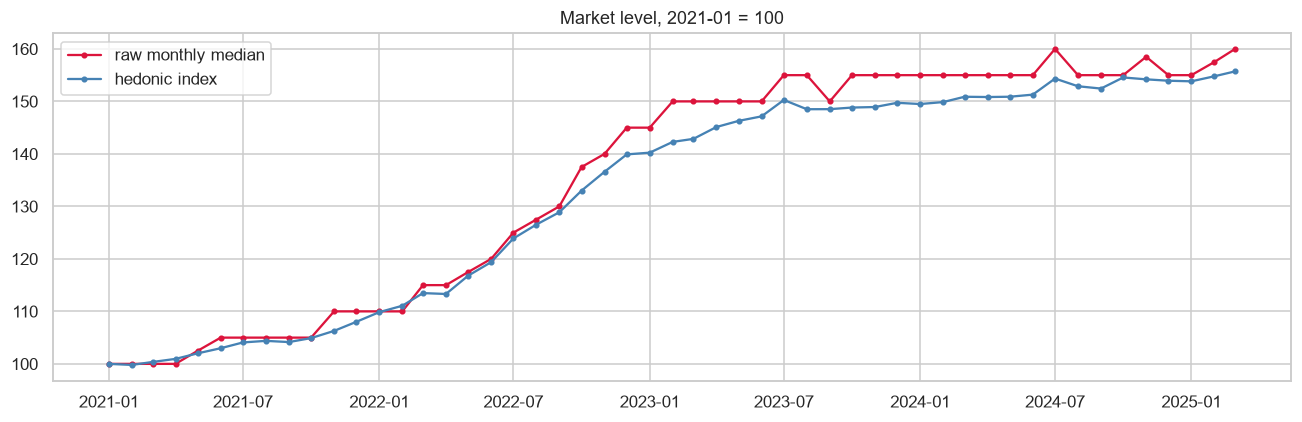

hedonic_r2                 0.552
rise_raw_median_pct       60.000
rise_hedonic_pct          55.720
distinct_values_raw       18.000
distinct_values_hedonic   50.000
dtype: float64

In [24]:
# Time-dummy hedonic index: log(rent) on flat and location attributes plus one dummy per month. The month
# coefficients are the market level with the flat mix held fixed.
attr = OneHotEncoder(drop="first", sparse_output=True).fit_transform(tr[["TOWN", "FLAT_TYPE", "FLAT_MODEL", "STREET"]])
month_dummies = OneHotEncoder(drop="first", sparse_output=True).fit_transform(tr[["MONTH_INDEX"]])
X_hedonic = sparse.hstack([attr, sparse.csr_matrix(tr[["FLOOR_AREA_SQM", "FLAT_AGE"]].to_numpy(float)), month_dummies]).tocsr()
hedonic_fit = LinearRegression().fit(X_hedonic, np.log(tr[TARGET]))
hedonic = pd.Series(np.r_[0.0, hedonic_fit.coef_[-month_dummies.shape[1]:]], index=raw_median.index)  # log, 2021-01 = 0
# In SGD, scaled so its log mean matches the raw median's. This is the market level for the rest of section 7.
market = np.exp(hedonic - hedonic.mean() + np.log(raw_median).mean())

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(raw_median.index, 100 * raw_median / raw_median.iloc[0], color="crimson", marker="o", ms=3, label="raw monthly median")
ax.plot(hedonic.index, 100 * np.exp(hedonic), color="steelblue", marker="o", ms=3, label="hedonic index")
ax.set_title("Market level, 2021-01 = 100")
ax.legend()
plt.tight_layout()
plt.show()

pd.Series({
    "share_of_rents_multiple_of_50": (tr[TARGET] % 50 == 0).mean(),
    "hedonic_r2": hedonic_fit.score(X_hedonic, np.log(tr[TARGET])),
    "rise_raw_median_pct": 100 * (raw_median.iloc[-1] / raw_median.iloc[0] - 1),
    "rise_hedonic_pct": 100 * (np.exp(hedonic.iloc[-1]) - 1),
    "distinct_values_raw": raw_median.nunique(),
    "distinct_values_hedonic": hedonic.round(4).nunique(),
})

Continuous, with the flat mix held fixed. It rises ~56% against +60% for the raw median: about 4 points of the
headline rise was flat mix. The plateau is not flat either: +4% from 2023-12 to 2025-03, hidden by the grid.

**`market` is this index from here on.** It is fitted once on all of train, so its attribute coefficients see later
months: a mild leak in 7.5 and 7.6. Refit it per validation origin when modelling.

### 7.2 Trend, seasonality and stationarity

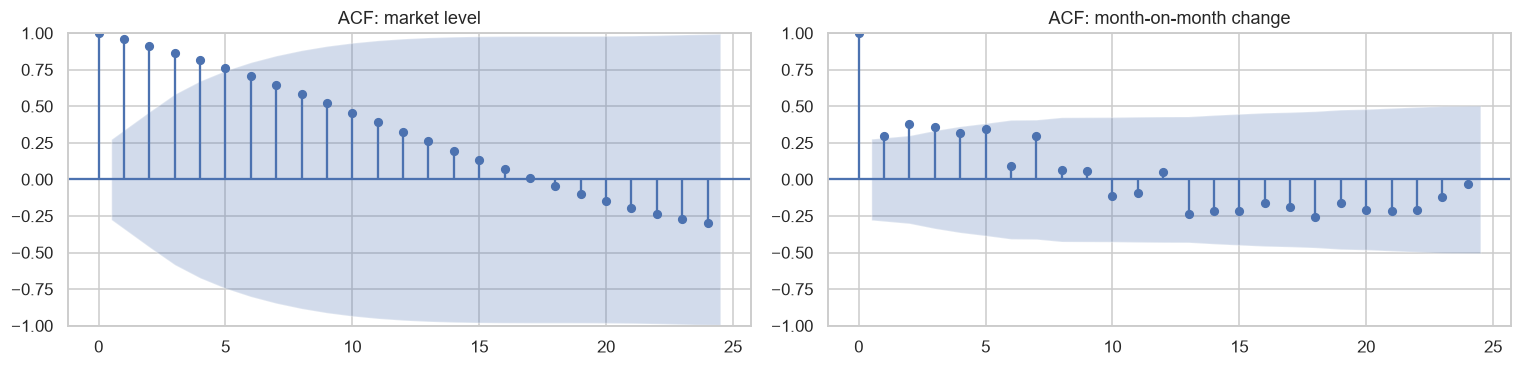

,adf_statistic,p_value
level,-1.579,0.494
month-on-month change,-2.065,0.259


In [26]:
# A slowly decaying ACF on the level = trend-dominated, non-stationary. The differenced series should show a spike
# at lag 12 if there were real seasonality.
fig, axes = plt.subplots(1, 2, figsize=(14, 3.5))
plot_acf(market, lags=24, ax=axes[0], title="ACF: market level")
plot_acf(market.diff().dropna(), lags=24, ax=axes[1], title="ACF: month-on-month change")
plt.tight_layout()
plt.show()

pd.DataFrame(
    [adfuller(s, autolag="AIC", result_object=False)[:2] for s in [market, market.diff().dropna()]],
    index=["level", "month-on-month change"], columns=["adf_statistic", "p_value"],
)

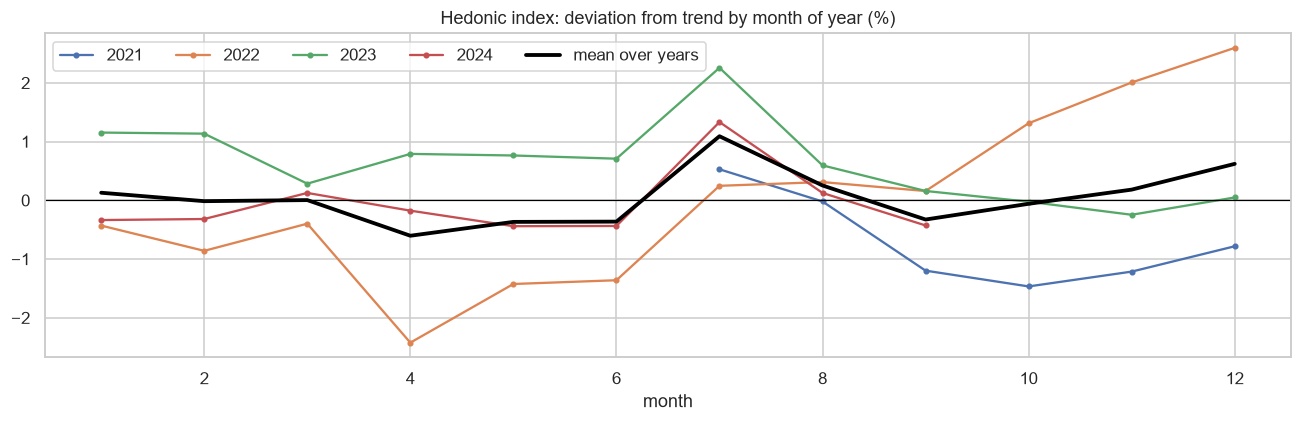

months used: 39 (2021-07 to 2024-09)
peak-to-trough of mean month effects: 1.69%  (about SGD 54 at the last level)
month-level F-test: F=0.62, p=0.793
leave-one-year-out correlation (other years' effects vs held-out year):
2021    0.350
2022   -0.510
2023   -0.060
2024    0.740


In [28]:
# Month-of-year effects on the hedonic index. Detrend with a centred 2x12 moving average (loses 6 months at each
# end), then ask the only question that matters with four cycles: does one year's pattern predict another's?
ma = hedonic.rolling(12, center=True).mean()
detrended = (hedonic - (ma + ma.shift(-1)) / 2).dropna()
by_year = pd.DataFrame({"year": detrended.index.year, "month": detrended.index.month, "dev": 100 * detrended.to_numpy()})
effects = by_year.groupby("month")["dev"].mean()

fig, ax = plt.subplots(figsize=(12, 4))
for year, grp in by_year.groupby("year"):
    ax.plot(grp["month"], grp["dev"], marker="o", ms=3, label=str(year))
ax.plot(effects.index, effects, color="black", lw=2.5, label="mean over years")
ax.axhline(0, c="black", lw=0.8)
ax.set_title("Hedonic index: deviation from trend by month of year (%)")
ax.set_xlabel("month")
ax.legend(ncol=5)
plt.tight_layout()
plt.show()

loyo = {}
for year, grp in by_year.groupby("year"):
    others = by_year[by_year["year"] != year].groupby("month")["dev"].mean()
    held = grp.set_index("month")["dev"]
    loyo[year] = np.corrcoef(others[held.index], held)[0, 1]

# Month-level F-test: 39 months in 12 groups. This is the honest sample size for a month-of-year effect, because
# rows in the same month share one market shock.
f_stat, p_val = stats.f_oneway(*[g["dev"].to_numpy() for _, g in by_year.groupby("month")])
print(f"months used: {len(detrended)} ({detrended.index[0]:%Y-%m} to {detrended.index[-1]:%Y-%m})")
print(f"peak-to-trough of mean month effects: {np.ptp(effects):.2f}%  (about SGD {np.ptp(effects) / 100 * market.iloc[-1]:.0f} at the last level)")
print(f"month-level F-test: F={f_stat:.2f}, p={p_val:.3f}")
print("leave-one-year-out correlation (other years' effects vs held-out year):")
print(pd.Series(loyo).round(2).to_string())

- **Trend dominates.** ACF ≈ 0.96 at lag 1.
- **Not stationary.** ADF cannot reject a unit root, even for monthly changes (low power: 51 points, one regime change).
- **No usable seasonality.** Peak-to-trough ~1.7% (about SGD 54). Leave-one-year-out correlations: +0.35, −0.51,
  −0.06, +0.74. Month-level F-test: p ≈ 0.79.
- July is above trend in all four years (~1.1%), but that was found post hoc with n = 4.

**Do not model month-of-year.**

### 7.3 Premiums over the market level are static

No flat ID, so these are repeated cross-sections, not a panel: a flat's own past rent is not available. Streets, flat
types and towns do repeat. If their premiums are stable *in relative terms*, rent is the market level multiplied by a
time-invariant shape.

In [29]:
months_per_address = tr.groupby("ADDRESS")["RENT_APPROVAL_DATE"].nunique()
print("distinct months per address (25/50/75%):", months_per_address.quantile([0.25, 0.5, 0.75]).to_dict())

# Relative rent = rent / that month's market level. A street's premium is its median relative rent in a quarter.
relative_rent = tr[TARGET] / tr["RENT_APPROVAL_DATE"].map(market)
street_quarter = (
    pd.DataFrame({"STREET": tr["STREET"], "QUARTER": tr["RENT_APPROVAL_DATE"].dt.to_period("Q"), "rel": relative_rent})
    .groupby(["STREET", "QUARTER"])["rel"].agg(["median", "size"])
    .query("size >= 20")["median"]  # quarters with too few rows give a noisy premium
    .unstack()
)
next_quarter_r = pd.Series({
    f"{a} -> {b}": street_quarter[[a, b]].dropna().corr().iloc[0, 1]
    for a, b in zip(street_quarter.columns[:-1], street_quarter.columns[1:])
})
first_last_r = street_quarter.iloc[:, [0, -1]].dropna().corr().iloc[0, 1]
print(f"street premium, quarter vs next quarter : mean r = {next_quarter_r.mean():.2f} (min {next_quarter_r.min():.2f})")
print(f"street premium, first vs last quarter   : r = {first_last_r:.2f}")

distinct months per address (25/50/75%): {0.25: 7.0, 0.5: 12.0, 0.75: 18.0}
street premium, quarter vs next quarter : mean r = 0.83 (min 0.74)
street premium, first vs last quarter   : r = 0.85


In [30]:
# Flat-type median rent as a multiple of the 4-room median, per year. Absolute gaps widen as the market rises;
# the question is whether the ratios do.
flat_year = tr.pivot_table(index="APPROVAL_YEAR", columns="FLAT_TYPE", values=TARGET, aggfunc="median")
flat_year.div(flat_year["4-room"], axis=0)

FLAT_TYPE,1-room,2-room,3-room,4-room,5-room,executive
APPROVAL_YEAR,,,,,,
2021,0.545,0.682,0.841,1.000,1.023,1.045
2022,0.520,0.716,0.880,1.000,1.080,1.120
2023,0.594,0.719,0.844,1.000,1.062,1.094
2024,0.515,0.697,0.848,1.000,1.061,1.091
2025,0.545,0.697,0.848,1.000,1.061,1.121


In [31]:
town_year = tr.pivot_table(index="TOWN", columns="APPROVAL_YEAR", values=TARGET, aggfunc="median")
town_premium = town_year / town_year.median()  # town median as a multiple of the median town, per year
print(f"town ranking, 2021 vs 2024: Spearman = {stats.spearmanr(town_year[2021], town_year[2024])[0]:.2f}")

premium_change = (town_premium[2024] - town_premium[2021]).sort_values().to_frame("premium_change_2021_to_2024")
pd.concat([premium_change.head(3), premium_change.tail(3)])

town ranking, 2021 vs 2024: Spearman = 0.89


,premium_change_2021_to_2024
TOWN,
bukit timah,-0.115
bukit merah,-0.115
bishan,-0.084
sembawang,-0.013
sengkang,-0.006
punggol,0.018


- **Streets:** the first and last quarter, four years apart, correlate as highly as adjacent quarters.
- **Flat types:** ratios stay within ~7 points of 2021 while the market rose ~50%.
- **Towns:** ranking Spearman ≈ 0.9. Exception: central older towns (Bukit Timah, Bukit Merah, Bishan) lost 8 to 12
  points of premium, a second-order town × time interaction.

**Premiums can be encoded statically; only the market level moves.**

### 7.4 Random K-fold vs. time-ordered validation

Same simple model, same rows, scored two ways:

- **random 5-fold:** the model sees later months
- **time split:** trained on earlier years only, as the test set requires

In [33]:
X = pd.DataFrame({
    "MONTH_INDEX": tr["MONTH_INDEX"],
    "FLOOR_AREA_SQM": tr["FLOOR_AREA_SQM"],
    "FLAT_AGE": tr["FLAT_AGE"],
    # Level names sort in size order ("1-room" ... "5-room", "executive"), so sorted codes are ordinal.
    "FLAT_TYPE": tr["FLAT_TYPE"].map({t: i for i, t in enumerate(sorted(tr["FLAT_TYPE"].unique()))}),
    "TOWN": tr["TOWN"].astype("category").cat.codes,
    "FLAT_MODEL": tr["FLAT_MODEL"].astype("category").cat.codes,
})
y = tr[TARGET]


def make_model():
    return HistGradientBoostingRegressor(categorical_features=["TOWN", "FLAT_MODEL"], max_iter=300, random_state=0)


random_pred = pd.Series(
    cross_val_predict(make_model(), X, y, cv=KFold(5, shuffle=True, random_state=0)), index=tr.index
)

rows = []
for year in [2022, 2023, 2024]:
    past, this = tr["APPROVAL_YEAR"] < year, tr["APPROVAL_YEAR"] == year
    time_pred = make_model().fit(X[past], y[past]).predict(X[this])
    rows.append({
        "year": year,
        "random_cv_mae": (random_pred[this] - y[this]).abs().mean(),
        "time_split_mae": np.abs(time_pred - y[this]).mean(),
        "random_cv_bias": (random_pred[this] - y[this]).mean(),
        "time_split_bias": (time_pred - y[this]).mean(),
    })
validation = pd.DataFrame(rows).set_index("year")
validation["random_cv_optimism_%"] = 100 * (validation["time_split_mae"] / validation["random_cv_mae"] - 1)
validation

,random_cv_mae,time_split_mae,random_cv_bias,time_split_bias,random_cv_optimism_%
year,,,,,
2022,397.604,475.529,-1.512,-310.516,19.599
2023,487.778,519.730,0.119,-128.433,6.550
2024,368.887,380.293,-0.942,-38.566,3.092


- **Random K-fold is optimistic in every year.**
- **It hides bias.** Mean error is ~0 under K-fold; under the time split the model systematically under-predicts.
- **The penalty scales with how far the market moves after the cutoff**, which is unknown for the test window.

### 7.5 Where the gap comes from

Fit **relative rent** (rent ÷ market level) with no time feature on earlier years, then convert back to SGD with:

- the **true** level of the predicted year (an oracle), or
- the **last known** level (median of the final 3 training months).

In [34]:
X_static = X.drop(columns="MONTH_INDEX")

rows = []
for year in [2022, 2023, 2024]:
    past, this = tr["APPROVAL_YEAR"] < year, tr["APPROVAL_YEAR"] == year
    rel_pred = make_model().fit(X_static[past], relative_rent[past]).predict(X_static[this])
    true_level = tr.loc[this, "RENT_APPROVAL_DATE"].map(market)
    last_known_level = market[market.index < f"{year}-01-01"].iloc[-3:].mean()
    rows.append({
        "year": year,
        "static_model_x_true_level_mae": np.abs(rel_pred * true_level - y[this]).mean(),
        "random_cv_mae": validation.loc[year, "random_cv_mae"],
        "static_model_x_last_known_level_mae": np.abs(rel_pred * last_known_level - y[this]).mean(),
        "time_split_mae": validation.loc[year, "time_split_mae"],
    })
pd.DataFrame(rows).set_index("year")

,static_model_x_true_level_mae,random_cv_mae,static_model_x_last_known_level_mae,time_split_mae
year,,,,
2022,401.181,397.604,485.429,475.529
2023,492.987,487.778,545.836,519.730
2024,369.811,368.887,379.736,380.293


With the true level, the time-blind model scores within ~1% of random K-fold; with the last known level it lands
within ~5% of the time split. **The whole validation gap is the market level.**

Floor: even with the level known exactly, MAE stays around SGD 370 to 490.

### 7.6 Forecasting the market level

Since the market level is the crux, compare simple ways of extrapolating it. Fit on 2021–2023, forecast
2024-01 … 2025-03 (15 months, close to the 16-month test horizon).

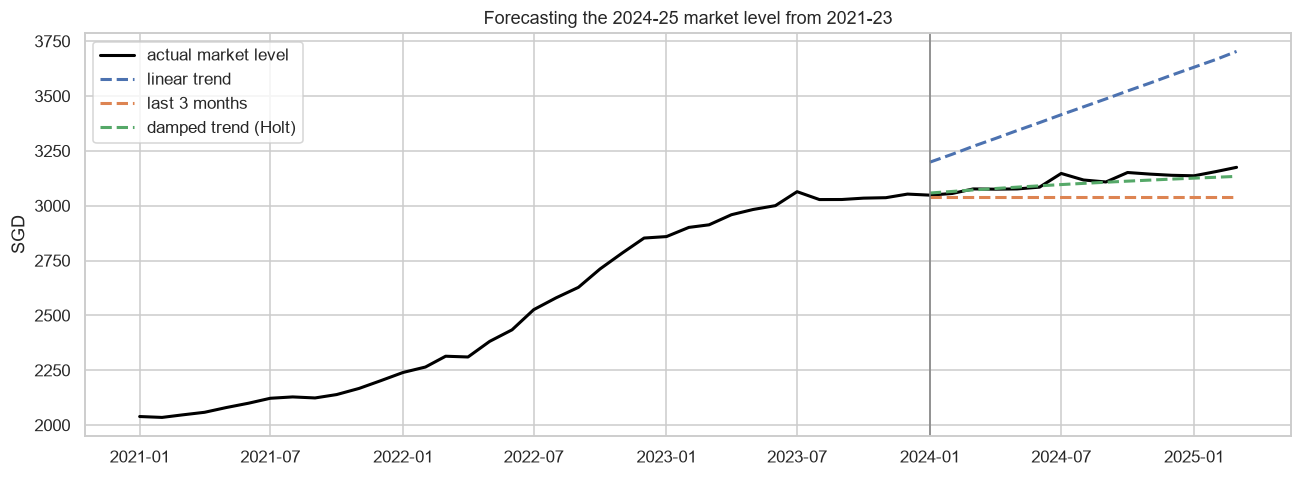

,mae,bias,forecast_at_2025_03
linear trend,338.219,338.219,"3,703.260"
last 3 months,71.382,-71.382,"3,041.215"
damped trend (Holt),18.023,-13.197,"3,133.594"


In [35]:
fit_part, holdout = market[:"2023-12"], market["2024-01":]
horizon = len(holdout)
future_steps = np.arange(len(fit_part), len(fit_part) + horizon)

forecasts = pd.DataFrame({
    "linear trend": np.polyval(np.polyfit(np.arange(len(fit_part)), fit_part.to_numpy(), 1), future_steps),
    "last 3 months": fit_part.iloc[-3:].mean(),
    "damped trend (Holt)": ExponentialSmoothing(fit_part, trend="add", damped_trend=True).fit().forecast(horizon).to_numpy(),
}, index=holdout.index)

fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(market.index, market, c="black", lw=2, label="actual market level")
for name in forecasts:
    ax.plot(forecasts.index, forecasts[name], ls="--", lw=2, label=name)
ax.axvline(pd.Timestamp("2024-01-01"), c="grey", lw=1)
ax.set_ylabel("SGD")
ax.set_title("Forecasting the 2024-25 market level from 2021-23")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

errors = forecasts.sub(holdout, axis=0)
pd.DataFrame({"mae": errors.abs().mean(), "bias": errors.mean(), "forecast_at_2025_03": forecasts.iloc[-1]})

In [36]:
# The model family makes this choice implicitly. A linear model extends MONTH_INDEX as a straight line; a tree
# ensemble cannot extrapolate and holds the last level it saw.
past, future = tr["APPROVAL_YEAR"] < 2024, tr["APPROVAL_YEAR"] >= 2024
X_onehot = pd.get_dummies(X, columns=["TOWN", "FLAT_MODEL"], drop_first=True, dtype=float)

ridge_err = Ridge(alpha=1.0).fit(X_onehot[past], y[past]).predict(X_onehot[future]) - y[future]
tree_err = make_model().fit(X[past], y[past]).predict(X[future]) - y[future]
pd.DataFrame({
    "ridge (straight-line time)": [ridge_err.abs().mean(), ridge_err.mean()],
    "gradient boosting (holds last level)": [tree_err.abs().mean(), tree_err.mean()],
}, index=["mae", "bias"]).T

,mae,bias
ridge (straight-line time),500.439,388.590
gradient boosting (holds last level),375.923,-46.580


A linear 2021 to 2023 trend overshoots the plateau by ~SGD 340, and ridge on `MONTH_INDEX` inherits that. The damped
trend is closest (MAE ~SGD 18). Holding the last level under-predicts by ~SGD 70, because the hedonic level kept
creeping up through 2024 (7.1). It is that close **only because the market flattened**: the same behaviour
under-predicted by ~SGD 300 in 2022 (7.4). One origin, so this is not a ranking of methods.

The level assumption for the test window is an explicit decision to justify and stress-test.

### 7.7 Train vs test feature drift

The test months all come after the train months, so a feature whose distribution shifts over time will be shifted
in the test set too.

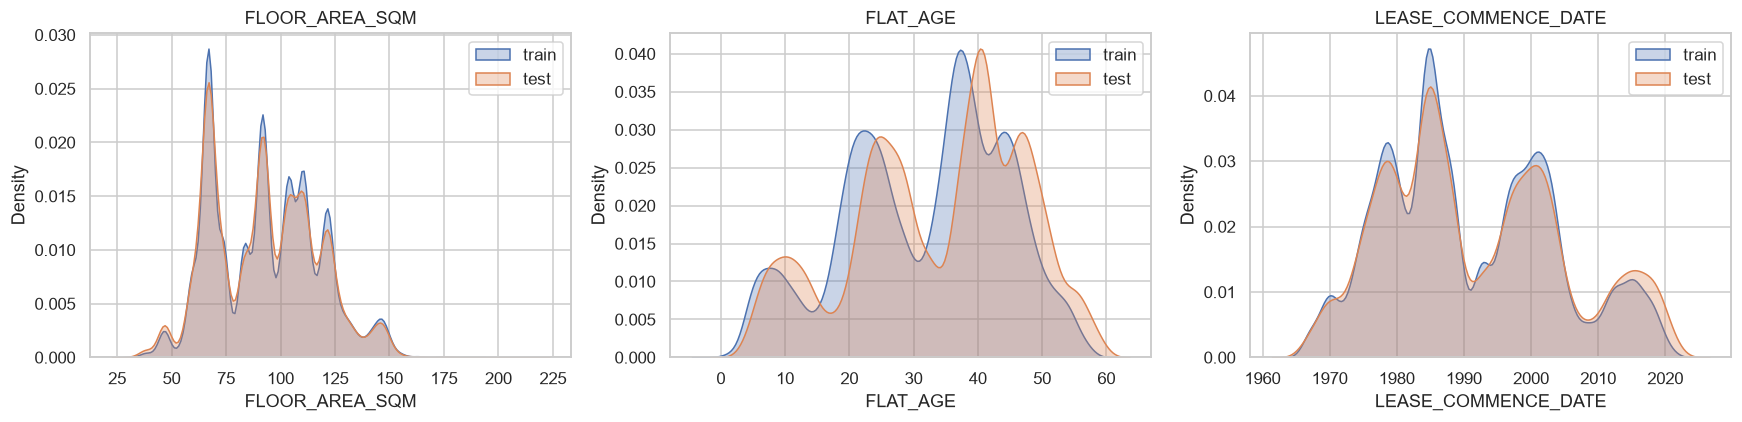

,train_%,test_%,diff
FLAT_TYPE,,,
1-room,0.028,0.024,-0.004
2-room,2.065,2.872,0.807
3-room,32.683,32.850,0.167
4-room,36.053,36.090,0.037
5-room,23.682,23.060,-0.622
executive,5.489,5.104,-0.385


In [37]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, c in zip(axes, ["FLOOR_AREA_SQM", "FLAT_AGE", "LEASE_COMMENCE_DATE"]):
    sns.kdeplot(tr[c], ax=ax, label="train", fill=True, alpha=0.3)
    sns.kdeplot(te[c], ax=ax, label="test", fill=True, alpha=0.3)
    ax.set_title(c)
    ax.legend()
plt.tight_layout()
plt.show()

comp = pd.DataFrame({
    "train_%": 100 * tr["FLAT_TYPE"].value_counts(normalize=True),
    "test_%": 100 * te["FLAT_TYPE"].value_counts(normalize=True),
}).sort_index()
comp["diff"] = comp["test_%"] - comp["train_%"]
comp

No material drift: floor area and lease year overlap, and flat-type shares move by under 1 point. `FLAT_AGE` shifts
up by about 2 years only because the test months are later.

### 7.8 Verdict

**A cross-sectional regression whose evaluation is a forecast.**

| part | behaves like | implication |
|---|---|---|
| relative premium | supervised learning (7.3, 7.5) | static encodings, fitted on earlier months only |
| market level | time series, up to 16 months ahead (7.1, 7.2) | a level assumption for the test window, stated and stress-tested |
| evaluation | out-of-time (7.4, 7.5) | time-ordered validation; report bias as well as MAE |

Rules out: random K-fold, target encoding on the full training set.

**Keep `MONTH_INDEX` in tree models, and know what it does.** A tree sends every month after the cutoff to the leaf of
the last training month, so it holds the market level where training ended (7.6). For the test window that is the
bet that rent stays at its early-2025 level through 2026-07. Write that down, report bias on every fold, and
stress-test it, e.g. by rescaling predictions ±3% and ±5%.

COE premiums and share prices do not replace `MONTH_INDEX`: in time-ordered folds they act as a noisy clock, never
clearly beat it, and many placebo series do as well on the plateau.

## 8. Encoding analysis

The deciding factors are cardinality, whether the levels have an inherent order, and how much of the test set
sits on levels never seen in train.

In [38]:
def one_hot_cost(df, cols):
    rows = []
    for c in cols:
        k = df[c].nunique()
        vc = df[c].value_counts()
        rows.append({
            "n_levels": k,
            "ohe_columns": k - 1,           
            "rows_per_level": len(df) / k,
            "levels_under_50_rows": int((vc < 50).sum()),
            "rarest_level_rows": int(vc.min()),
            "top_level_share_%": 100 * vc.iloc[0] / len(df),
        })
    return pd.DataFrame(rows, index=cols)


one_hot_cost(tr, ["TOWN", "FLAT_TYPE", "FLAT_MODEL", "STREET", "BLOCK", "ADDRESS", "APPROVAL_MONTH"])

,n_levels,ohe_columns,rows_per_level,levels_under_50_rows,rarest_level_rows,top_level_share_%
TOWN,26,25,"5,769.231",0,438,6.988
FLAT_TYPE,6,5,"25,000.000",1,42,36.053
FLAT_MODEL,20,19,"7,500.000",4,1,29.339
STREET,576,575,260.417,86,2,1.343
BLOCK,2720,2719,55.147,1946,1,0.614
ADDRESS,9406,9405,15.947,9181,1,0.091
APPROVAL_MONTH,12,11,"12,500.000",0,10803,10.900


### Verdict per column

| column | levels | encoding |
|---|---|---|
| `TOWN` | 26 | one-hot |
| `FLAT_MODEL` | 20 | one-hot; fold levels under 50 rows (`premium maisonette`, `terrace`, `3gen`, `improved maisonette`) into `other` |
| `FLAT_TYPE` | 6 | ordinal integer; 5-room and executive tie on median rent |
| `STREET` | 576 | target or frequency encoding |
| `ADDRESS` | 9,406 | smoothed target encoding, or join block coordinates and encode as geography; 50 levels unseen in test |
| `BLOCK` | 2,720 | drop; meaningless without its street |
| `LEASE_COMMENCE_DATE` | 57 | numeric (or `FLAT_AGE`) |
| `RENT_APPROVAL_DATE` | 51 | numeric `MONTH_INDEX`; one-hot cannot reach the test months |
| `APPROVAL_MONTH` | 12 | sin/cos at most; expect nothing (7.2) |
| `FURNISHED`, `FEE` | 1 | drop |

In [39]:
# FLAT_TYPE is ordinal, and the target confirms the order is monotone -- so an integer map is defensible.
FLAT_TYPE_ORDER = ["1-room", "2-room", "3-room", "4-room", "5-room", "executive"]
FLAT_TYPE_MAP = {t: i for i, t in enumerate(FLAT_TYPE_ORDER)}

check = (
    tr.groupby("FLAT_TYPE", observed=True)
    .agg(n=(TARGET, "size"), median_rent=(TARGET, "median"), median_sqm=("FLOOR_AREA_SQM", "median"))
    .reindex(FLAT_TYPE_ORDER)
)
check["ordinal_code"] = check.index.map(FLAT_TYPE_MAP)
check

,n,median_rent,median_sqm,ordinal_code
FLAT_TYPE,,,,
1-room,42,"1,450.000",31.000,0
2-room,3098,"2,100.000",47.000,1
3-room,49024,"2,350.000",67.000,2
4-room,54079,"2,800.000",93.000,3
5-room,35523,"3,000.000",118.000,4
executive,8234,"3,000.000",144.000,5


In [40]:
# APPROVAL_MONTH is cyclical: December and January are adjacent, which neither an integer nor a one-hot
# column expresses. Two columns instead of eleven.
month_cyc = pd.DataFrame({
    "MONTH_SIN": np.sin(2 * np.pi * tr["APPROVAL_MONTH"] / 12),
    "MONTH_COS": np.cos(2 * np.pi * tr["APPROVAL_MONTH"] / 12),
})
month_cyc.head(3)

,MONTH_SIN,MONTH_COS
0,0.500,0.866
1,0.500,0.866
2,0.500,0.866


In [41]:
# Frequency encoding: cheap, one column, no target leakage, works for any cardinality. Useful as a baseline
# for STREET/ADDRESS before reaching for target encoding.
freq_street = tr["STREET"].map(tr["STREET"].value_counts(normalize=True))
print("STREET frequency encoding ->", freq_street.describe()[["min", "50%", "max"]].to_dict())

# Target encoding, done wrong (fit on the full training set) leaks the target into rare levels.
naive = tr.groupby("ADDRESS", observed=True)[TARGET].mean()
counts = tr["ADDRESS"].value_counts()
print(f"\naddresses with a single row: {(counts == 1).sum():,} "
      f"({100 * (counts == 1).mean():.1f}% of levels) -- for those, the naive encoding IS the target")

STREET frequency encoding -> {'min': 1.3333333333333333e-05, '50%': 0.0029733333333333335, 'max': 0.013426666666666667}

addresses with a single row: 247 (2.6% of levels) -- for those, the naive encoding IS the target


In [42]:
# Smoothed target encoding, computed out-of-fold. m controls how hard a rare level is pulled toward the
# global mean. The unseen-level fallback is the global mean.
def smoothed_target_encode(train_s, target_s, m=20):
    prior = target_s.mean()
    agg = target_s.groupby(train_s, observed=True).agg(["count", "mean"])
    return ((agg["count"] * agg["mean"] + m * prior) / (agg["count"] + m)), prior


mapping, prior = smoothed_target_encode(tr["ADDRESS"], tr[TARGET], m=20)
pd.DataFrame({
    "raw_mean": tr.groupby("ADDRESS", observed=True)[TARGET].mean(),
    "n": tr["ADDRESS"].value_counts(),
    "smoothed": mapping,
}).sort_values("n").head(5)

,raw_mean,n,smoothed
ADDRESS,,,
609c tampines north drive 1,"3,350.000",1,"2,749.083"
131b canberra crescent,"2,850.000",1,"2,725.273"
131c canberra crescent,"3,500.000",1,"2,756.226"
612a tampines north drive 1,"3,000.000",1,"2,732.416"
359 yishun ring road,"2,700.000",1,"2,718.130"


> **Temporal split:** fit target encodings only on months strictly before the rows they encode. A random K-fold
> encoding leaks future rent levels (median rent rose ~60%) and flatters CV.

## 9. Distribution of every column

### 9.1 Target

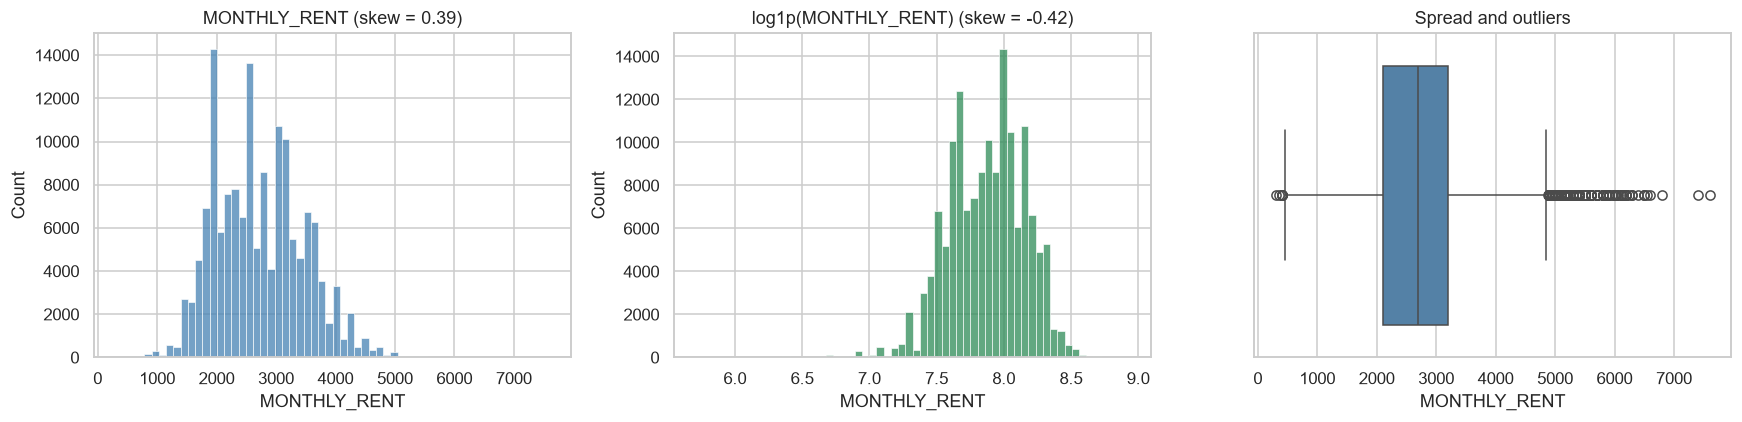

0.001     724.975
0.010   1,300.000
0.500   2,700.000
0.990   4,600.000
0.999   5,400.000

rent is discretised: 608 distinct values, 98.7% are multiples of 50


In [43]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(tr[TARGET], bins=60, ax=axes[0], color="steelblue")
axes[0].set_title(f"{TARGET} (skew = {tr[TARGET].skew():.2f})")

sns.histplot(np.log1p(tr[TARGET]), bins=60, ax=axes[1], color="seagreen")
axes[1].set_title(f"log1p({TARGET}) (skew = {np.log1p(tr[TARGET]).skew():.2f})")

sns.boxplot(x=tr[TARGET], ax=axes[2], color="steelblue")
axes[2].set_title("Spread and outliers")
plt.tight_layout()
plt.show()

q = tr[TARGET].quantile([0.001, 0.01, 0.5, 0.99, 0.999])
print(q.to_string())
print(f"\nrent is discretised: {tr[TARGET].nunique()} distinct values, "
      f"{100 * (tr[TARGET] % 50 == 0).mean():.1f}% are multiples of 50")

### 9.2 Numeric columns

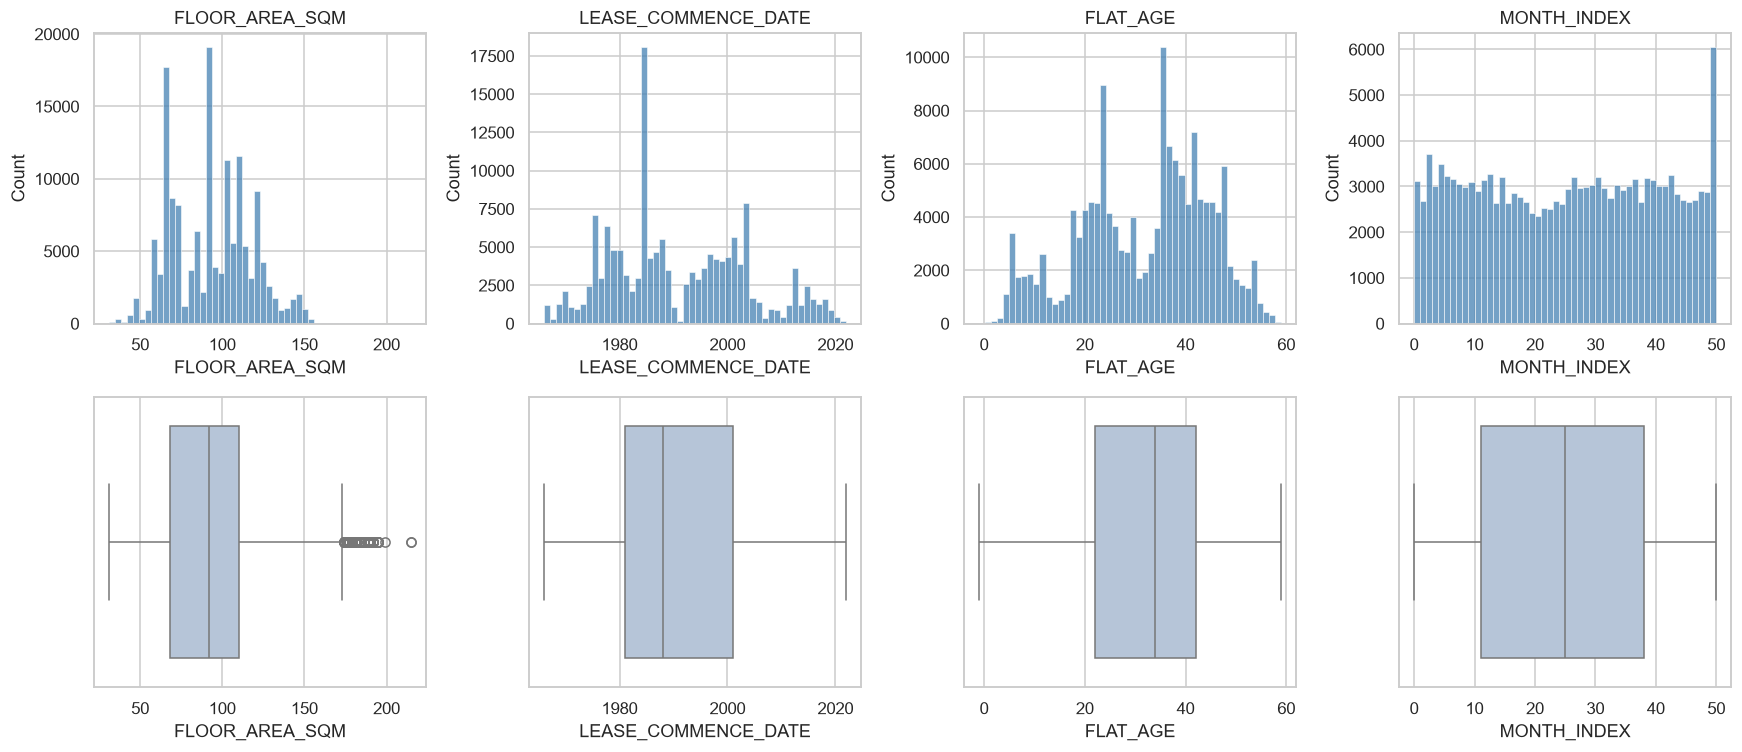

In [44]:
plot_num = ["FLOOR_AREA_SQM", "LEASE_COMMENCE_DATE", "FLAT_AGE", "MONTH_INDEX"]

fig, axes = plt.subplots(2, len(plot_num), figsize=(4 * len(plot_num), 7))
for i, c in enumerate(plot_num):
    sns.histplot(tr[c], bins=50, ax=axes[0, i], color="steelblue")
    axes[0, i].set_title(c)
    sns.boxplot(x=tr[c], ax=axes[1, i], color="lightsteelblue")
    axes[1, i].set_xlabel(c)
plt.tight_layout()
plt.show()

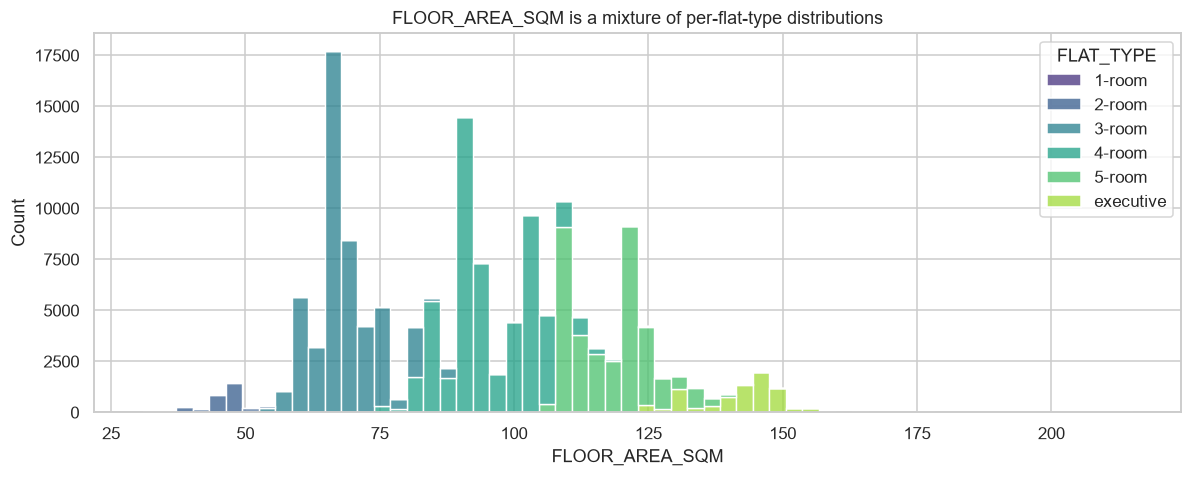

In [45]:
# FLOOR_AREA_SQM is multi-modal because it is really a proxy for flat type -- worth seeing the split.
plt.figure(figsize=(11, 4.5))
sns.histplot(
    tr, x="FLOOR_AREA_SQM", hue="FLAT_TYPE", bins=60, multiple="stack",
    hue_order=FLAT_TYPE_ORDER, palette="viridis",
)
plt.title("FLOOR_AREA_SQM is a mixture of per-flat-type distributions")
plt.tight_layout()
plt.show()

### 9.3 Categorical columns

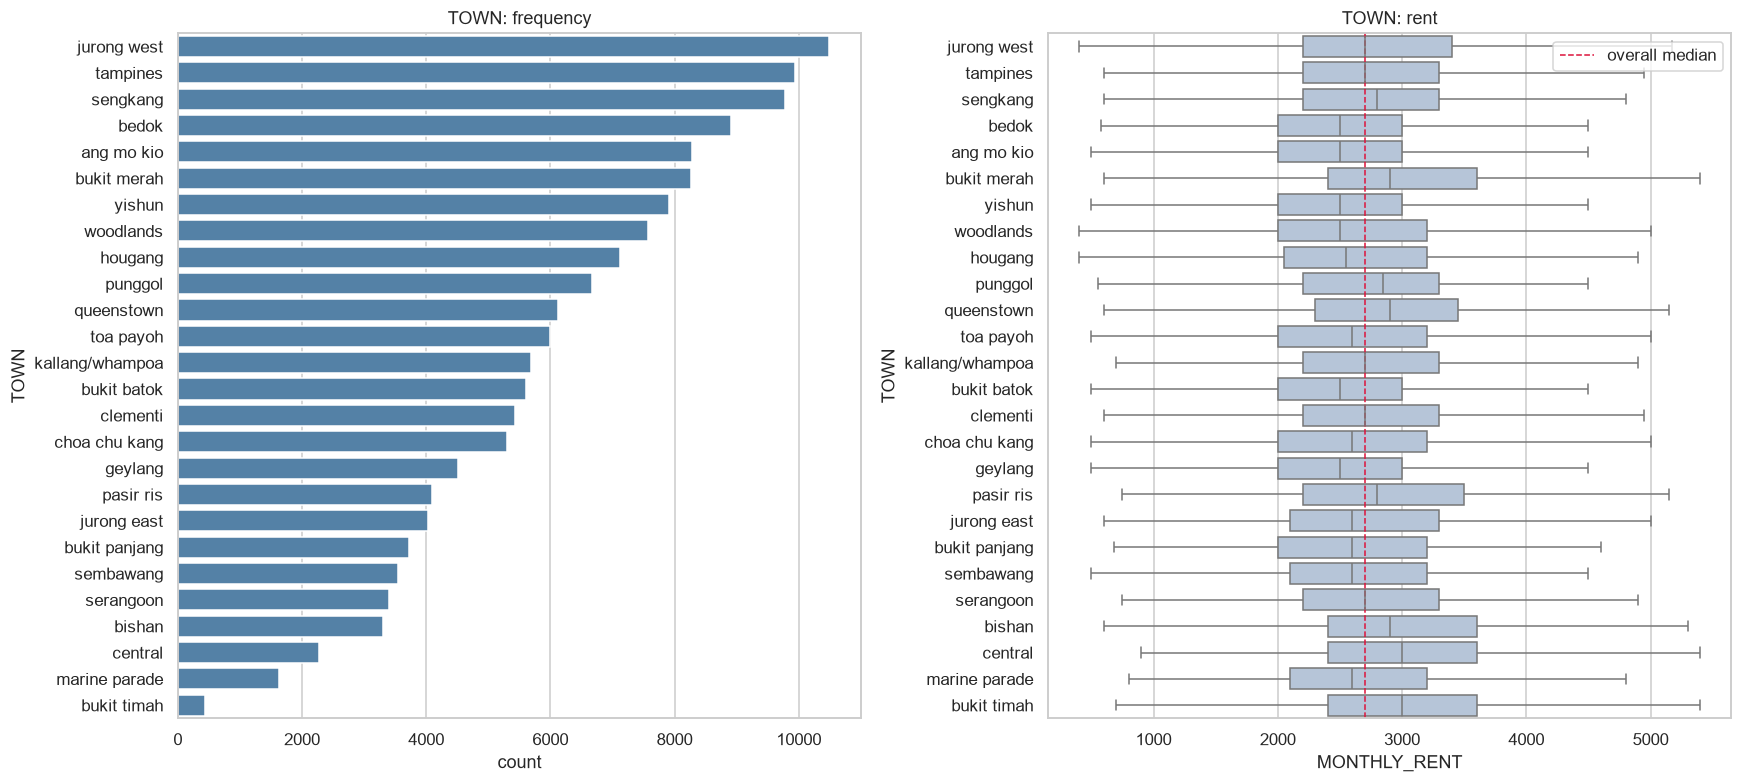

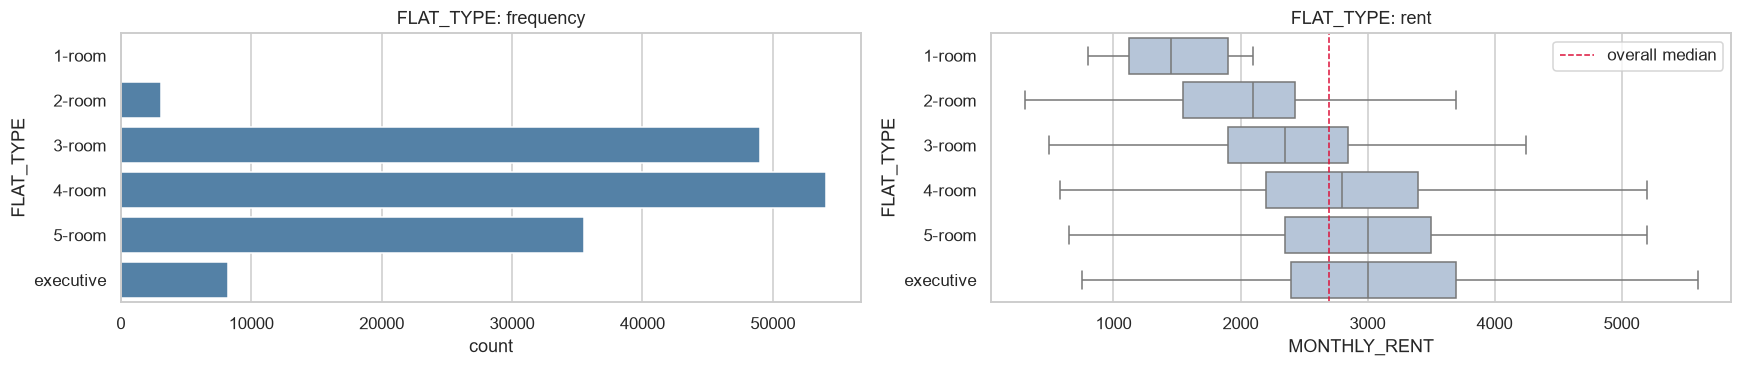

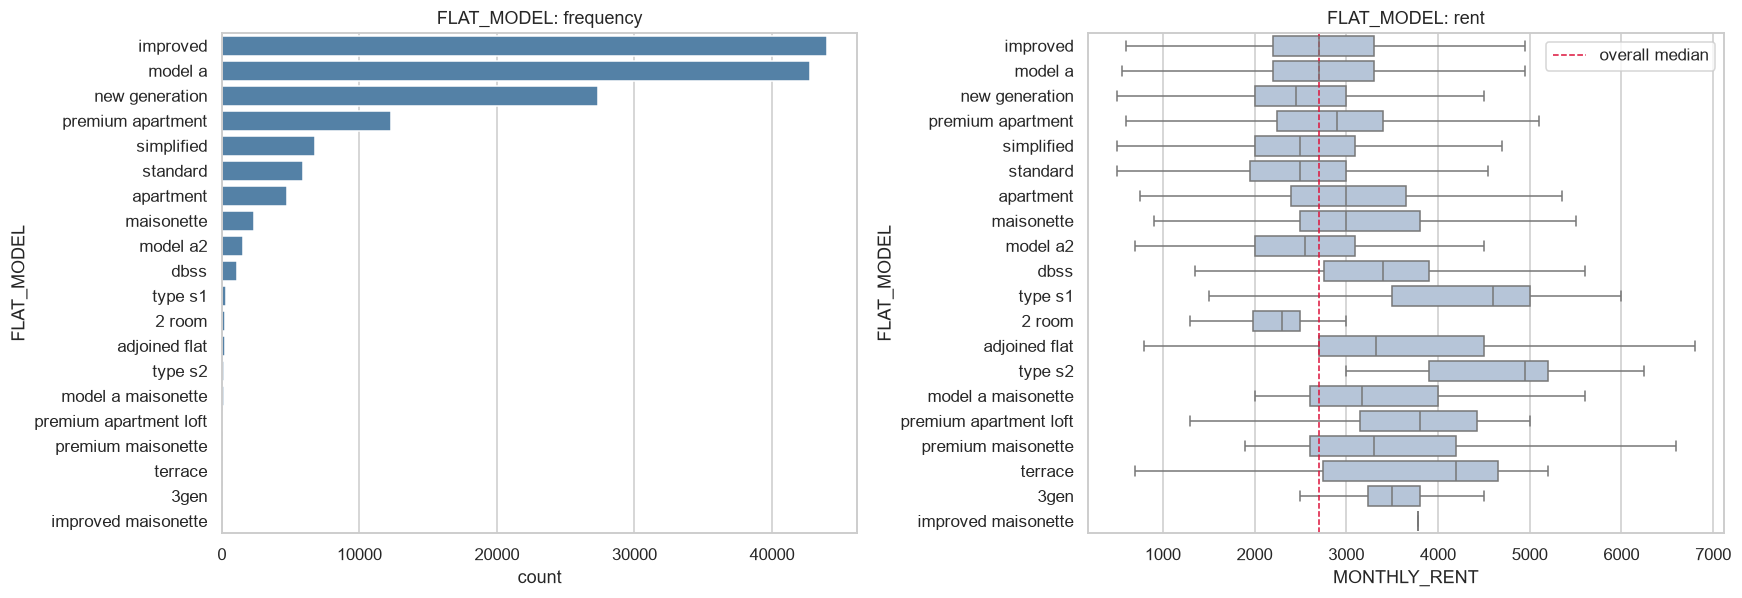

In [46]:
for c in ["TOWN", "FLAT_TYPE", "FLAT_MODEL"]:
    order = FLAT_TYPE_ORDER if c == "FLAT_TYPE" else tr[c].value_counts().index
    fig, axes = plt.subplots(1, 2, figsize=(16, max(3.5, 0.28 * tr[c].nunique())))

    sns.countplot(y=tr[c], order=order, ax=axes[0], color="steelblue")
    axes[0].set_title(f"{c}: frequency")

    sns.boxplot(data=tr, y=c, x=TARGET, order=order, ax=axes[1], color="lightsteelblue", showfliers=False)
    axes[1].axvline(tr[TARGET].median(), ls="--", c="crimson", lw=1, label="overall median")
    axes[1].set_title(f"{c}: rent")
    axes[1].legend()
    plt.tight_layout()
    plt.show()

In [47]:
# Rare levels: these are the ones to fold into "other" before one-hot encoding.
for c in ["FLAT_MODEL", "TOWN"]:
    vc = tr[c].value_counts()
    rare = vc[vc < 50]
    print(f"{c}: {len(rare)} level(s) with <50 rows -> {rare.to_dict()}")

FLAT_MODEL: 4 level(s) with <50 rows -> {'premium maisonette': 21, 'terrace': 19, '3gen': 12, 'improved maisonette': 1}
TOWN: 0 level(s) with <50 rows -> {}


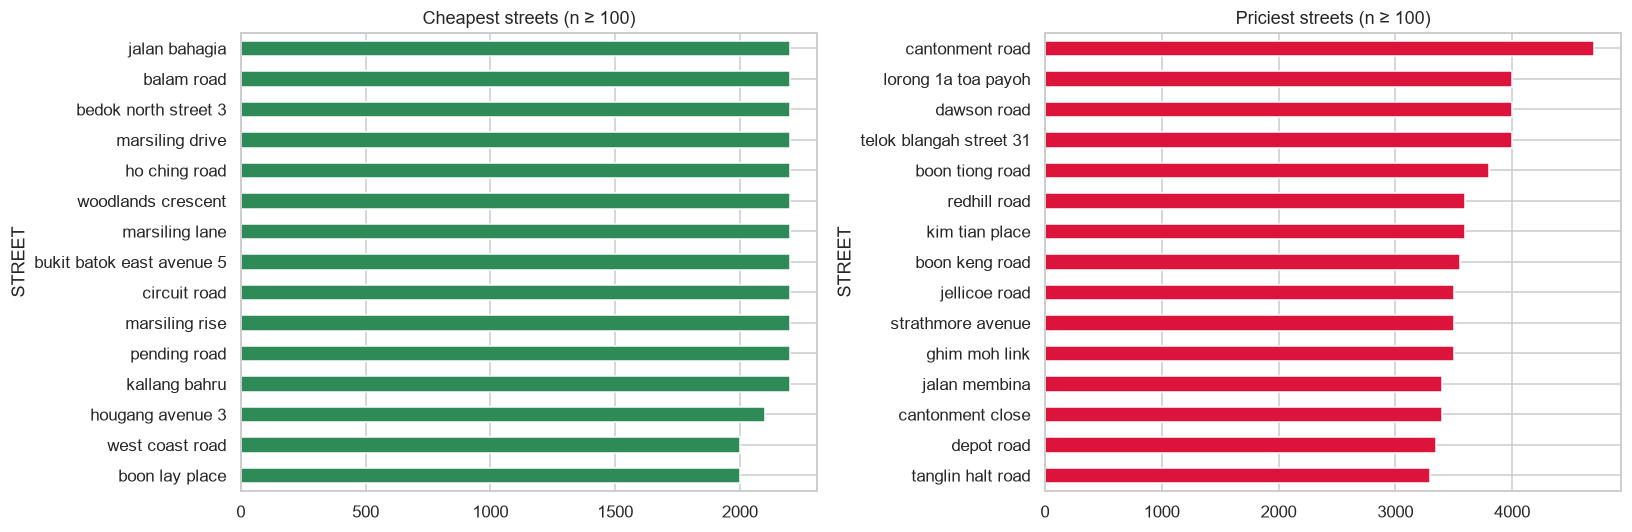

In [48]:
# Highest- and lowest-rent streets: the geographic signal that a target encoder would pick up.
street_stats = (
    tr.groupby("STREET", observed=True)
    .agg(n=(TARGET, "size"), median_rent=(TARGET, "median"))
    .query("n >= 100")
    .sort_values("median_rent")
)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
street_stats.head(15)["median_rent"].plot.barh(ax=axes[0], color="seagreen")
axes[0].set_title("Cheapest streets (n ≥ 100)")
street_stats.tail(15)["median_rent"].plot.barh(ax=axes[1], color="crimson")
axes[1].set_title("Priciest streets (n ≥ 100)")
plt.tight_layout()
plt.show()

## 10. Summary

- **Problem:** rent ≈ market level(month) × relative premium(flat, location). The premium is stable (supervised
  learning); the level must be forecast up to 16 months ahead (7.8).
- **Time:** market level = hedonic index (7.1). Rapid growth 2021 to 2023, plateau from 2024. No usable seasonality: under 2% and unstable across years (7.2).
- **Validation:** random K-fold is optimistic and hides an under-prediction of up to ~SGD 300. The whole gap is the
  market level (7.5).
- **Data quality:** `FURNISHED` and `FEE` are constant; `FLAT_TYPE` is spelled two ways (11 apparent levels, 6 real);
  street casing collapses 1,146 values to 576; no missing values; 425 duplicate rows; feature-identical rows with
  different rents set an error floor.
- **Signal:** time (Spearman ≈ 0.56 vs `MONTH_INDEX`) > `FLOOR_AREA_SQM` (0.33) > `LEASE_COMMENCE_DATE` (0.23).
  Location dominates the categoricals. `FLAT_TYPE`, `FLAT_MODEL` and `FLOOR_AREA_SQM` are collinear.
- **Encoding:** see the section 8 table; target encodings on earlier months only, ideally of relative rent.
- **Next:** refit the hedonic index per validation origin; keep `MONTH_INDEX` and stress-test the level it holds
  for the test window (7.8); join `sg-hdb-block.csv` coordinates, MRT, schools and malls for geographic features.